                            mpg  cylinders  displacement  horsepower  weight  \
name                                                                           
chevrolet chevelle malibu  18.0          8         307.0         130    3504   
buick skylark 320          15.0          8         350.0         165    3693   
plymouth satellite         18.0          8         318.0         150    3436   
amc rebel sst              16.0          8         304.0         150    3433   
ford torino                17.0          8         302.0         140    3449   

                           acceleration  year  origin  
name                                                   
chevrolet chevelle malibu          12.0    70       1  
buick skylark 320                  11.5    70       1  
plymouth satellite                 11.0    70       1  
amc rebel sst                      12.0    70       1  
ford torino                        10.5    70       1  


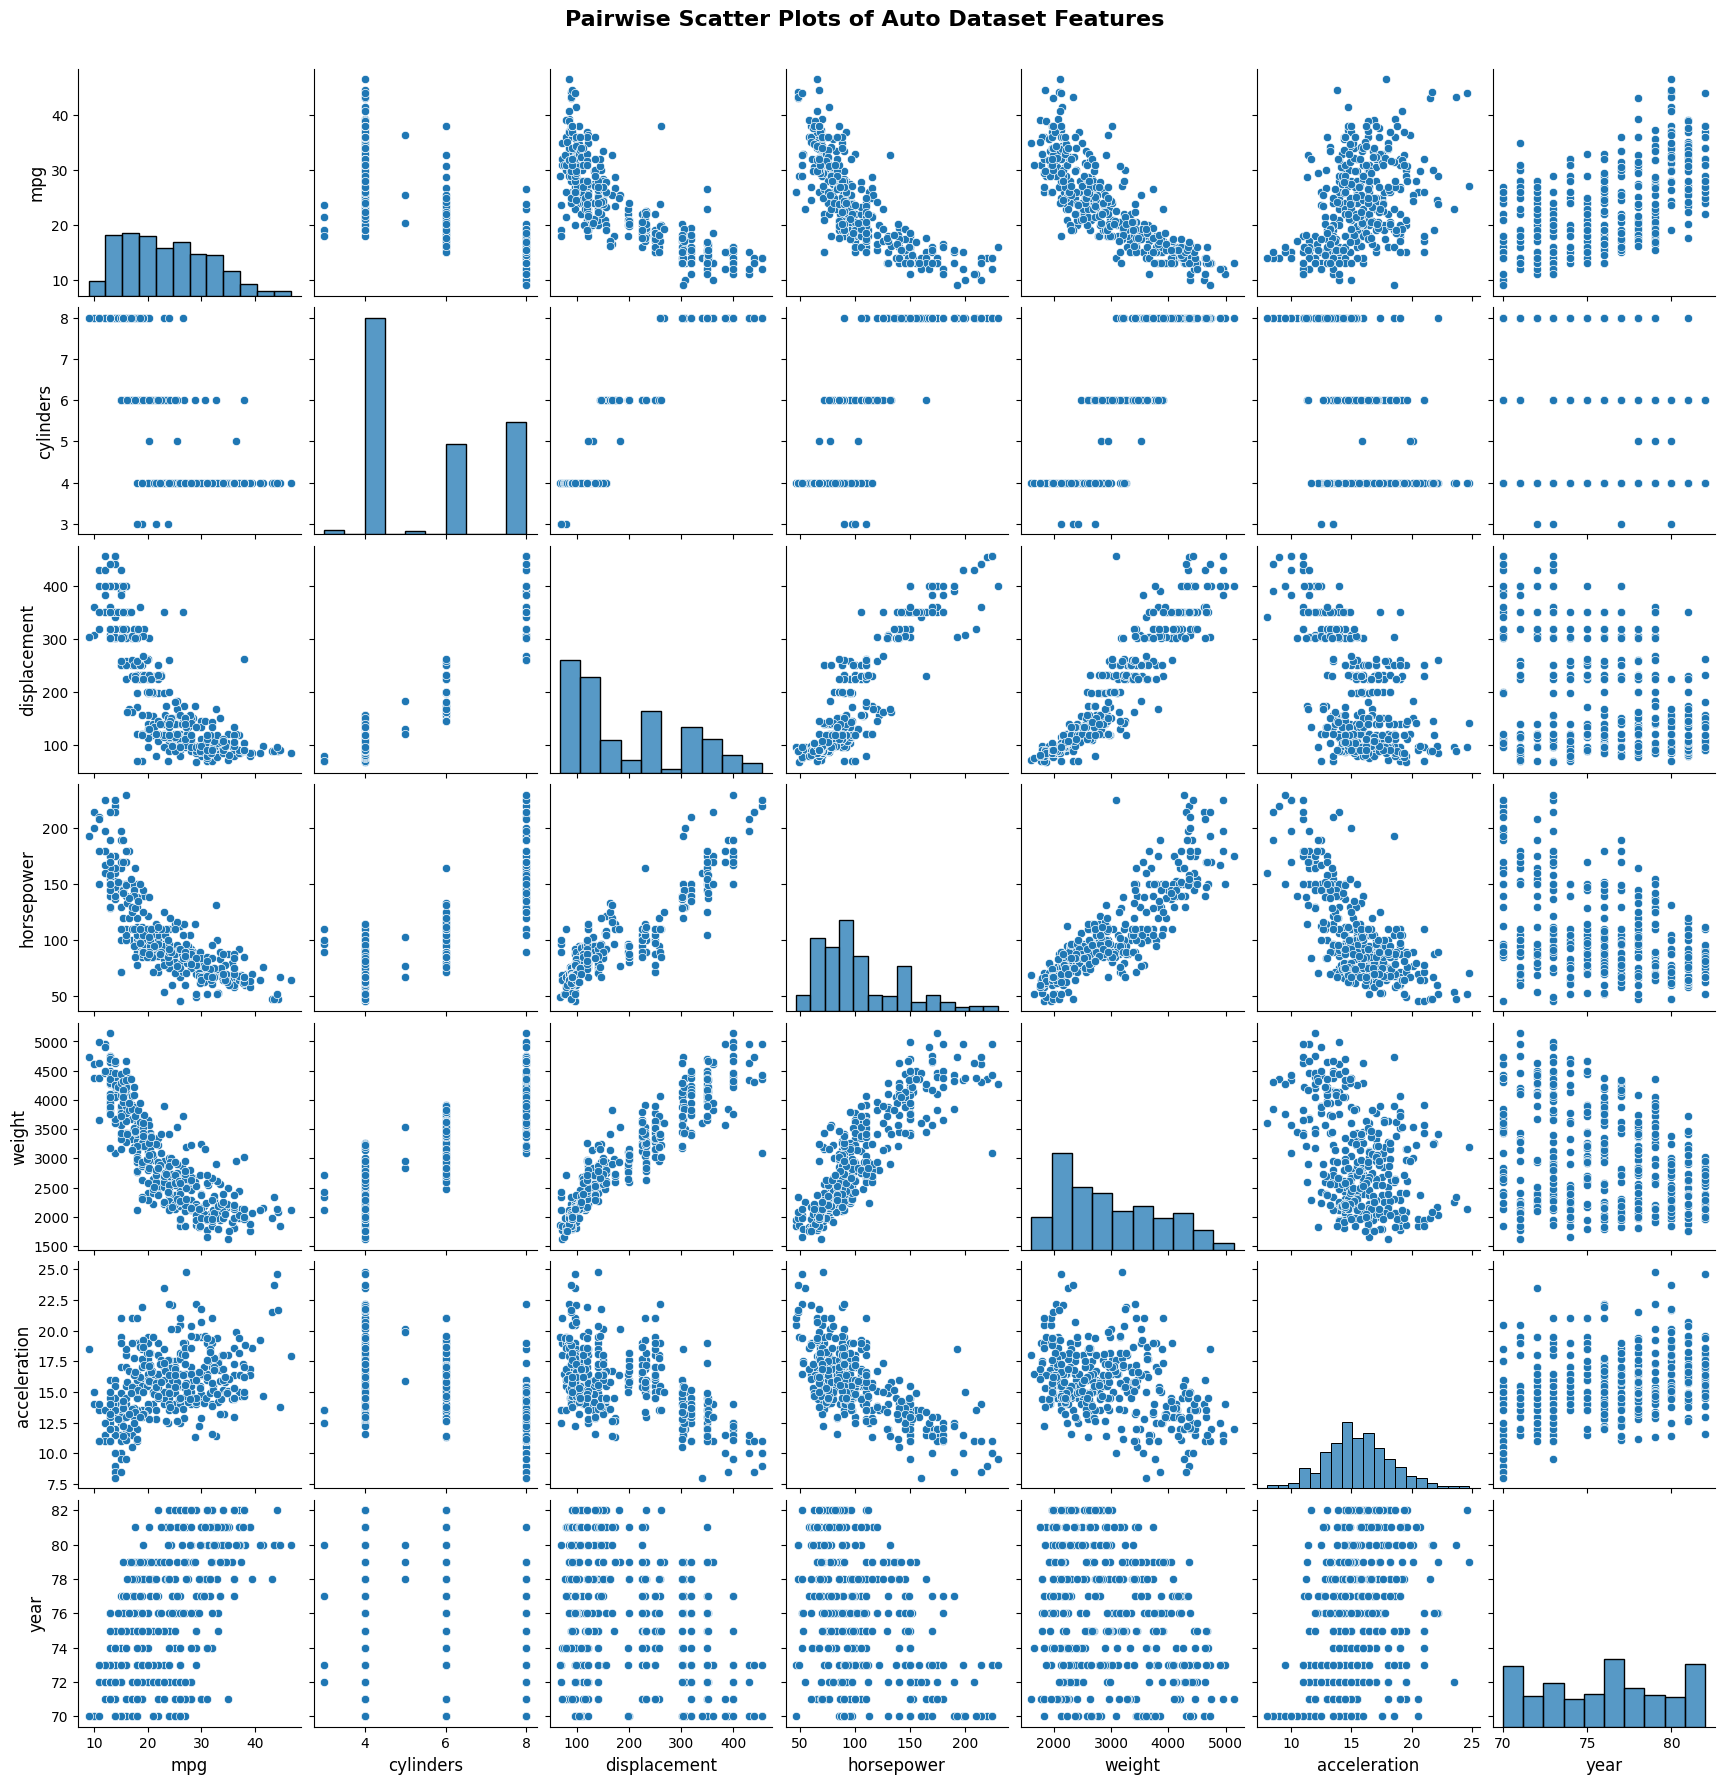

--- Model Results ---
Intercept (beta_0): 7403.93
None
Coefficients (beta_1, beta_2): [-293.58349802    4.0247245 ]
Mean Squared Error (MSE): 145364.62
R-squared (R2): 0.7980



/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but PolynomialFeatures was fitted with feature names
  warnings.warn(


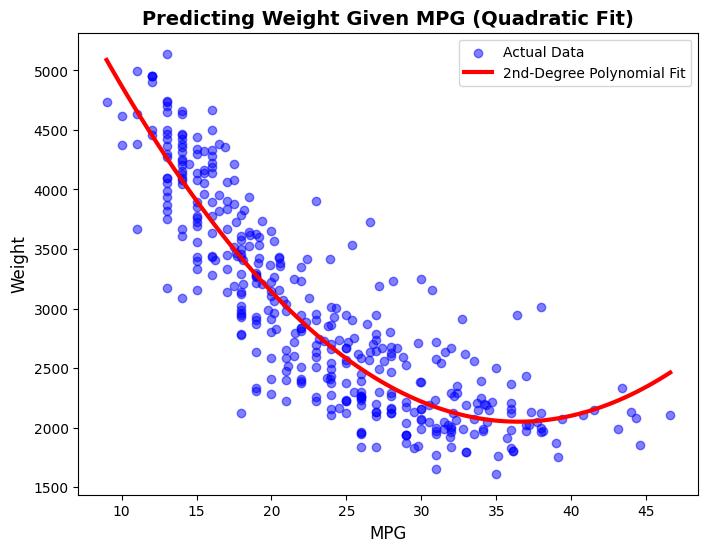

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


--- Reciprocal Model Results ---
Intercept (c): 816.97
Coefficient (m): 45179.94
Mean Squared Error (MSE): 155929.56
R-squared (R2): 0.7833



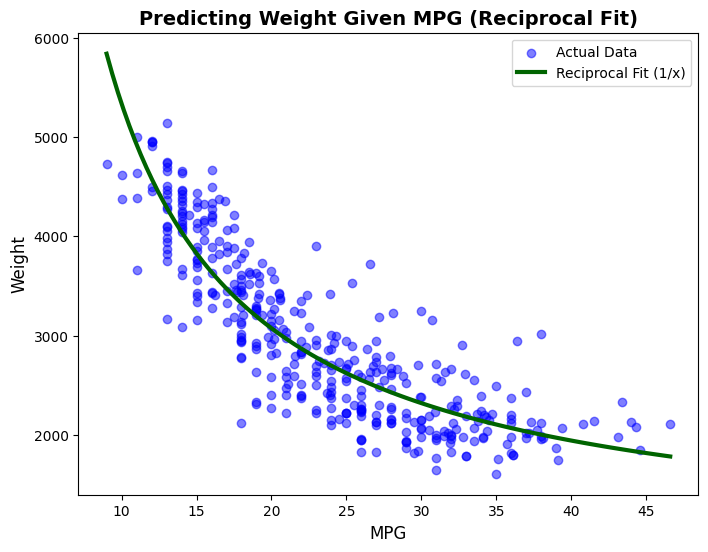

In [ ]:
# Week 4, Applied Question 8.

%pip install ISLP        # Using % magic command installs it directly from the cell

from ISLP import load_data
Auto = load_data('Auto')

Auto.head()

print(Auto.head())


# Plot all correlations

import matplotlib.pyplot as plt
import seaborn as sns

# Select the numeric columns
columns_to_plot = ['mpg', 'cylinders', 'displacement', 'horsepower', 'weight', 'acceleration', 'year']

# Generate the plot matrix with customized label sizes
g = sns.pairplot(Auto[columns_to_plot])

# Loop through the grid to customize individual axis titles/labels
for ax in g.axes.flat:
    if ax is not None:
        # Increase axis label font size and add spacing
        ax.xaxis.label.set_size(12)
        ax.yaxis.label.set_size(12)

# Add a global title over the entire matrix
g.figure.suptitle('Pairwise Scatter Plots of Auto Dataset Features', y=1.02, fontsize=16, fontweight='bold')

plt.show()



# Fit a 2nd-degree polynomial model

import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.metrics import mean_squared_error, r2_score

# 1. Define independent (X) and dependent (y) variables
# Note: We reshape X because sklearn expects a 2D array for features
X = Auto[['mpg']]
y = Auto['weight']

# 2. Transform the feature into 2nd-degree polynomial features (X and X^2)
poly = PolynomialFeatures(degree=2, include_bias=False)
X_poly = poly.fit_transform(X)

# 3. Fit the linear regression model on the polynomial features
poly_model = LinearRegression()
poly_model.fit(X_poly, y)

# 4. Generate predictions
y_pred = poly_model.predict(X_poly)

# 5. Evaluate the model performance
mse = mean_squared_error(y, y_pred)
r2 = r2_score(y, y_pred)

print("--- Model Results ---")
print(print(f"Intercept (beta_0): {poly_model.intercept_:.2f}"))
print(f"Coefficients (beta_1, beta_2): {poly_model.coef_}")
print(f"Mean Squared Error (MSE): {mse:.2f}")
print(f"R-squared (R2): {r2:.4f}\n")

# 6. Plot the original data points and the regression curve
plt.figure(figsize=(8, 6))
plt.scatter(X, y, color='blue', alpha=0.5, label='Actual Data')

# Create a smooth line for the prediction curve by sorting X
X_fit = np.linspace(X.min(), X.max(), 100).reshape(-1, 1)
X_fit_poly = poly.transform(X_fit)
y_fit = poly_model.predict(X_fit_poly)

plt.plot(X_fit, y_fit, color='red', linewidth=3, label='2nd-Degree Polynomial Fit')
plt.xlabel('MPG', fontsize=12)
plt.ylabel('Weight', fontsize=12)
plt.title('Predicting Weight Given MPG (Quadratic Fit)', fontsize=14, fontweight='bold')
plt.legend()
plt.show()


# Fit the y = b1/x + b0

import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# 1. Define independent (X) and dependent (y) variables
X = Auto[['mpg']]
y = Auto['weight']

# 2. Transform the feature into its reciprocal (1/x)
X_reciprocal = 1.0 / X

# 3. Fit the linear regression model on the transformed feature
recip_model = LinearRegression()
recip_model.fit(X_reciprocal, y)

# 4. Generate predictions
y_pred_recip = recip_model.predict(X_reciprocal)

# 5. Evaluate the model performance
mse_recip = mean_squared_error(y, y_pred_recip)
r2_recip = r2_score(y, y_pred_recip)

print("--- Reciprocal Model Results ---")
print(f"Intercept (c): {recip_model.intercept_:.2f}")
print(f"Coefficient (m): {recip_model.coef_[0]:.2f}")
print(f"Mean Squared Error (MSE): {mse_recip:.2f}")
print(f"R-squared (R2): {r2_recip:.4f}\n")

# 6. Plot the original data points and the reciprocal curve
plt.figure(figsize=(8, 6))
plt.scatter(X, y, color='blue', alpha=0.5, label='Actual Data')

# Create a smooth line for the prediction curve by generating range for X
X_fit = np.linspace(X.min(), X.max(), 100).reshape(-1, 1)
X_fit_reciprocal = 1.0 / X_fit
y_fit_recip = recip_model.predict(X_fit_reciprocal)

plt.plot(X_fit, y_fit_recip, color='darkgreen', linewidth=3, label='Reciprocal Fit (1/x)')
plt.xlabel('MPG', fontsize=12)
plt.ylabel('Weight', fontsize=12)
plt.title('Predicting Weight Given MPG (Reciprocal Fit)', fontsize=14, fontweight='bold')
plt.legend()
plt.show()


